# Notebook 1 — Dataset Validation and Exploratory Analysis

**Project:** Auditable Long-Memory Retrieval for Bank Model Risk Management  
**Dataset:** AMREB v1.0.0  
**Student:** Kalirajan Natarajan

This notebook validates the synthetic benchmark and documents its composition before any model is trained. It checks scale, split isolation, missing values, class balance, and duplicate identifiers. The frozen test questions are counted but never used for fitting, tuning, or inspection.

In [1]:
from pathlib import Path
import json, sys

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
(ROOT / 'results' / 'figures').mkdir(parents=True, exist_ok=True)
print('Project root:', ROOT)
print('Frozen test split accessed:', False)

Project root: <PROJECT_ROOT>
Frozen test split accessed: False


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from src.baseline import load_jsonl

documents = pd.DataFrame(load_jsonl(ROOT / 'data' / 'documents.jsonl'))
questions = pd.DataFrame(load_jsonl(ROOT / 'data' / 'questions.jsonl'))
summary = {
    'documents': len(documents),
    'questions': len(questions),
    'model_families': documents['model_id'].nunique(),
    'document_types': documents['document_type'].nunique(),
    'duplicate_document_ids': int(documents['document_id'].duplicated().sum()),
    'duplicate_question_ids': int(questions['question_id'].duplicated().sum()),
    'missing_document_cells': int(documents.isna().sum().sum()),
    'missing_question_cells': int(questions.isna().sum().sum()),
}
summary

Matplotlib is building the font cache; this may take a moment.


{'documents': 72,
 'questions': 120,
 'model_families': 6,
 'document_types': 9,
 'duplicate_document_ids': 0,
 'duplicate_question_ids': 0,
 'missing_document_cells': 120,
 'missing_question_cells': 0}

In [3]:
split_counts = questions.groupby('split').size().rename('questions').to_frame()
category_counts = questions.groupby(['split', 'category']).size().unstack(fill_value=0)
display(split_counts)
display(category_counts)

,questions
split,
development,30
test,30
train,60


category,conflicting_evidence,cross_document_synthesis,direct_retrieval,temporal_update,unanswerable_abstention
split,,,,,
development,6,6,6,6,6
test,6,6,6,6,6
train,12,12,12,12,12


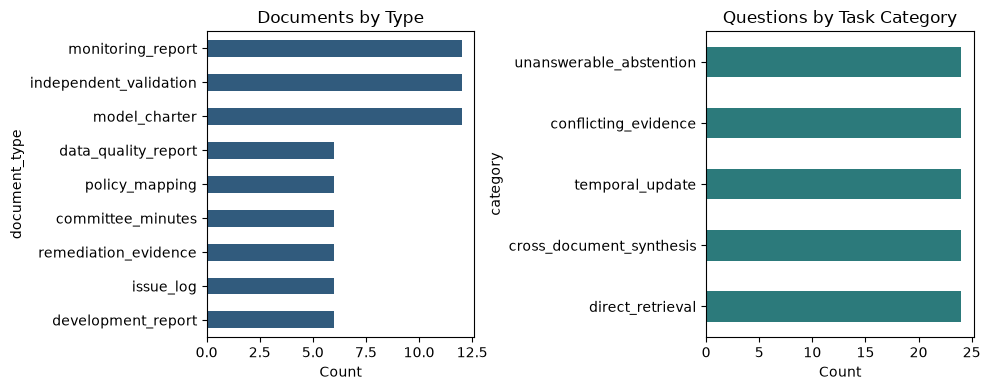

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
documents['document_type'].value_counts().sort_values().plot.barh(ax=axes[0], color='#315B7D')
axes[0].set_title('Documents by Type'); axes[0].set_xlabel('Count')
questions['category'].value_counts().sort_values().plot.barh(ax=axes[1], color='#2C7A7B')
axes[1].set_title('Questions by Task Category'); axes[1].set_xlabel('Count')
fig.tight_layout()
fig.savefig(ROOT / 'results' / 'figures' / 'dataset_composition.png', dpi=180, bbox_inches='tight')
plt.show()

In [5]:
checks = {
    'expected_72_documents': len(documents) == 72,
    'expected_120_questions': len(questions) == 120,
    'split_60_30_30': split_counts['questions'].to_dict() == {'development': 30, 'test': 30, 'train': 60},
    'unique_document_ids': not documents['document_id'].duplicated().any(),
    'unique_question_ids': not questions['question_id'].duplicated().any(),
    'all_gold_ids_exist': all(set(ids).issubset(set(documents['document_id'])) for ids in questions['gold_document_ids']),
}
assert all(checks.values()), checks
checks

{'expected_72_documents': True,
 'expected_120_questions': True,
 'split_60_30_30': True,
 'unique_document_ids': True,
 'unique_question_ids': True,
 'all_gold_ids_exist': True}

## Interpretation

AMREB is balanced by model family and task category and contains no real customer data. Empty expiration dates are intentional for current documents, not accidental missingness. The dataset includes superseded records, conflicting evidence, and unanswerable questions so that temporal reasoning, citation, and abstention can be measured—not merely topical similarity.